# Project 2 · Milestone 1 — Baseline Prompt→Image Generation (Stable Diffusion 1.5)

**Goal:** generate images for **15 prompts** taken from our curated captions using a **pretrained** Stable Diffusion 1.5, and compare each one side by side with the real Flickr30k photo for that caption. No training happens here: this is the baseline that later milestones improve on.

Outputs:
- a side-by-side gallery (ground truth vs. generated) for the gallery memo
- CLIP scores that put numbers on how well each image matches its prompt
- a diversity test (same prompt, different seeds) for the mode-collapse discussion
- `baseline_gallery.md`, a Markdown gallery ready to export to PDF

**Runtime:** Colab with a **T4 GPU**. About 5–8 minutes (most of it is downloading the model the first time).

## 1. Install

In [1]:
!pip install -q diffusers transformers accelerate
!pip uninstall -y -q torchao

## 2. Settings
`GUIDANCE_SCALE` controls how strongly the image follows the prompt (7.5 is Stable Diffusion's standard default). Each prompt gets a fixed seed so the exact same images can be regenerated later.

In [2]:
import os, json, time, textwrap
import numpy as np
import pandas as pd
import torch
from PIL import Image
import matplotlib.pyplot as plt

SEED           = 42
SD_MODEL       = "stable-diffusion-v1-5/stable-diffusion-v1-5"   # official mirror of RunwayML's SD 1.5
CLIP_MODEL     = "openai/clip-vit-large-patch14"                 # for scoring
N_PROMPTS      = 15          # assignment asks for 10–20
STEPS          = 30          # denoising steps
GUIDANCE_SCALE = 7.5
SIZE           = 512

DATA_DIR = "data/flickr30k_subset"
ZIP_PATH = "flickr30k_subset.zip"     # or "/content/drive/MyDrive/flickr30k_subset.zip"
OUT_DIR  = "baseline_gallery"
os.makedirs(os.path.join(OUT_DIR, "generated"), exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype  = torch.float16 if device == "cuda" else torch.float32
print("device:", device, "| GPU:", torch.cuda.get_device_name(0) if device == "cuda" else "none")
if device == "cpu":
    print("WARNING: no GPU. Generation on CPU takes several minutes per image. "
          "Runtime -> Change runtime type -> T4 GPU.")

device: cuda | GPU: Tesla T4


## 3. Load the dataset from notebook 1
**No upload needed.** If `flickr30k_subset.zip` from notebook 1 is in the file panel, this cell unzips it. If not, it rebuilds the exact same 2,000 pairs from Hugging Face (about 5 minutes). The **check code** at the end must say *same as notebook 1*.

In [3]:
import os, re, json, glob, shutil, zipfile, hashlib
import numpy as np, pandas as pd
from PIL import Image

def rebuild_dataset():
    # Rebuilds the same 2,000 pairs as notebook 1 straight from Hugging Face (about 5 minutes).
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets", "imagehash"], check=True)
    import imagehash
    from datasets import load_dataset
    _SEED, TARGET_PAIRS, IMG_SIZE, MIN_SIDE, MAX_ASPECT = 42, 2000, 512, 256, 2.0
    MIN_WORDS, MAX_WORDS, TARGET_WORDS, NEAR_DUP_DIST = 6, 30, 15, 4
    IMG_DIR = os.path.join(DATA_DIR, "images")
    os.makedirs(IMG_DIR, exist_ok=True)

    BLOCKLIST = {"nude", "naked", "topless", "sexy", "blood", "bloody", "gun", "guns",
                 "rifle", "pistol", "weapon", "weapons", "corpse", "kill", "killing"}

    def clean_caption(text):
        t = text.strip()
        t = re.sub(r"\s+([.,!;:'])", r"\1", t)
        t = re.sub(r"\s+", " ", t)
        t = t.strip(" .")
        if t:
            t = t[0].upper() + t[1:]
        return t

    def word_count(t):
        return len(t.split())

    def caption_ok(t):
        n = word_count(t)
        if n < MIN_WORDS or n > MAX_WORDS or "?" in t:
            return False
        if sum(c.isalpha() for c in t) / max(len(t), 1) < 0.7:
            return False
        return not (set(re.findall(r"[a-z]+", t.lower())) & BLOCKLIST)

    def pick_caption(captions):
        valid = []
        for c in captions:
            c = clean_caption(c)
            if caption_ok(c) and c not in valid:
                valid.append(c)
        if not valid:
            return None, []
        return min(valid, key=lambda c: abs(word_count(c) - TARGET_WORDS)), valid

    def center_crop_resize(img):
        img = img.convert("RGB")
        w, h = img.size
        s = min(w, h)
        left, top = (w - s) // 2, (h - s) // 2
        return img.crop((left, top, left + s, top + s)).resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)

    ds = load_dataset("lmms-lab-encoder/flickr30k", split="test", streaming=True).shuffle(seed=_SEED, buffer_size=2000)
    records, seen_captions, seen_hashes = [], set(), []
    for ex in ds:
        img = ex["image"]
        w, h = img.size
        if min(w, h) < MIN_SIDE or max(w, h) / min(w, h) > MAX_ASPECT:
            continue
        best, valid = pick_caption(ex["caption"])
        if best is None or best.lower() in seen_captions:
            continue
        ph = imagehash.phash(img.convert("RGB"))
        if any(ph - prev <= NEAR_DUP_DIST for prev in seen_hashes):
            continue
        fname = os.path.splitext(ex["filename"])[0] + ".jpg"
        center_crop_resize(img).save(os.path.join(IMG_DIR, fname), quality=95)
        seen_captions.add(best.lower())
        seen_hashes.append(ph)
        records.append({"image_id": ex["img_id"], "filename": fname, "caption": best,
                        "n_words": word_count(best), "alt_captions": json.dumps(valid),
                        "orig_width": w, "orig_height": h})
        if len(records) % 250 == 0:
            print(f"kept {len(records)} / {TARGET_PAIRS}")
        if len(records) >= TARGET_PAIRS:
            break

    df = pd.DataFrame(records).sample(frac=1, random_state=_SEED).reset_index(drop=True)
    n = len(df)
    df["split"] = ["train"] * int(0.8 * n) + ["val"] * int(0.1 * n) + ["test"] * (n - int(0.8 * n) - int(0.1 * n))
    df.to_csv(os.path.join(DATA_DIR, "metadata.csv"), index=False)

def find_zips():
    found = glob.glob("*.zip") + glob.glob("*/*.zip")
    return [z for z in found if "flickr30k" in z.lower() and zipfile.is_zipfile(z)]

if not os.path.exists(os.path.join(DATA_DIR, "metadata.csv")):
    zips = ([ZIP_PATH] if os.path.exists(ZIP_PATH) and zipfile.is_zipfile(ZIP_PATH) else []) + find_zips()
    if zips:
        zip_path = max(zips, key=os.path.getsize)
        shutil.unpack_archive(zip_path, DATA_DIR)
        print("Unzipped", zip_path)
    else:
        print("No zip uploaded, so rebuilding the dataset from Hugging Face (about 5 minutes)...")
        rebuild_dataset()

df = pd.read_csv(os.path.join(DATA_DIR, "metadata.csv"))
check = hashlib.md5("|".join(sorted(df["filename"] + ":" + df["split"])).encode()).hexdigest()[:10]
print("pairs:", len(df), df["split"].value_counts().to_dict())
print("check code:", check, "(same as notebook 1)" if check == "477c680542" else "(DIFFERENT from notebook 1)")

pairs: 2000 {'train': 1600, 'val': 200, 'test': 200}
check code: 477c680542 (same as notebook 1)


## 4. Pick 15 representative prompts
"Representative" means covering the different kinds of scenes in the dataset, not 15 photos of people walking. We take prompts from the **test split** only (so we never tune on them later) and pick about two per scene type.

In [4]:
import re

DOMAINS = {
    "people":        ["man", "woman", "men", "women", "person", "people", "boy", "girl", "child", "children"],
    "animals":       ["dog", "dogs", "cat", "horse", "bird", "animal", "cow", "sheep"],
    "sports":        ["ball", "soccer", "football", "basketball", "bike", "bicycle", "skateboard", "player"],
    "water / beach": ["water", "beach", "ocean", "lake", "river", "pool", "swimming", "surf"],
    "city / street": ["street", "city", "building", "sidewalk", "road", "crowd"],
    "nature":        ["grass", "field", "tree", "trees", "mountain", "snow", "forest"],
    "indoor":        ["room", "kitchen", "table", "restaurant", "store", "stage"],
}

pool = df[df["split"] == "test"].sample(frac=1, random_state=SEED)
chosen, used = [], set()
# Specific domains first, then "people" last (almost every caption mentions people)
order = [d for d in DOMAINS if d != "people"] + ["people"]
per_domain = max(1, N_PROMPTS // len(DOMAINS))
for d in order:
    pattern = r"\b(?:" + "|".join(DOMAINS[d]) + r")\b"
    hits = pool[pool["caption"].str.lower().str.contains(pattern) & ~pool["filename"].isin(used)]
    for _, row in hits.head(per_domain).iterrows():
        chosen.append({**row.to_dict(), "domain": d}); used.add(row["filename"])
for _, row in pool[~pool["filename"].isin(used)].iterrows():   # top up to N_PROMPTS
    if len(chosen) >= N_PROMPTS: break
    chosen.append({**row.to_dict(), "domain": "other"}); used.add(row["filename"])

prompts = pd.DataFrame(chosen[:N_PROMPTS]).reset_index(drop=True)
pd.set_option("display.max_colwidth", 120)
display(prompts[["domain", "caption"]])

,domain,caption
0,animals,A tan dog running through the grass with the background blurry
1,animals,A dog with golden fur is chest deep in water
2,sports,A man in a number ten jersey kicks a soccer ball while another team member watches
3,sports,A person jumping their bike in the woods in front of trees with no leaves
4,water / beach,Men and women in bathing suits are standing at poolside while another swimmer is in the water
5,water / beach,Boy heads into water big tents and hills in background in rural area
6,city / street,Five people on bikes in traffic with man watching from the side of the road
7,city / street,People are walking on the slippery road in winter and there are two dogs: black and yellow
8,nature,A couple and their child pose for a picture in front of a Christmas tree
9,nature,Three dogs who are brown white and black ( respectively ) play with one another in a dirt field


## 5. Load Stable Diffusion 1.5
The pipeline has three parts:
- **CLIP text encoder:** turns the prompt into 77 token vectors (the same encoder as notebook 2)
- **U-Net:** starts from random noise in a small **latent space** (64×64×4) and removes noise step by step, guided by the text through cross-attention
- **VAE decoder:** turns the final latent into a 512×512 image

We keep Stable Diffusion's built-in **safety checker** on; it blacks out any output it flags as unsafe.

In [5]:
from diffusers import StableDiffusionPipeline

pipe = StableDiffusionPipeline.from_pretrained(SD_MODEL, torch_dtype=dtype)
pipe = pipe.to(device=device, dtype=dtype)
pipe.set_progress_bar_config(disable=True)
print("U-Net parameters:", round(sum(p.numel() for p in pipe.unet.parameters()) / 1e6), "M")
print("scheduler:", type(pipe.scheduler).__name__)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


U-Net parameters: 860 M
scheduler: PNDMScheduler


## 6. Generate one image per prompt
Each prompt uses its own fixed seed (`SEED + i`), so every image is reproducible. This is **conditional sampling**: drawing a random sample from the model's image distribution *given* the text.

In [6]:
rows = []
for i, r in prompts.iterrows():
    g = torch.Generator(device=device).manual_seed(SEED + i)
    t0 = time.time()
    out = pipe(r["caption"], num_inference_steps=STEPS, guidance_scale=GUIDANCE_SCALE,
               height=SIZE, width=SIZE, generator=g)
    secs = time.time() - t0
    img = out.images[0]
    flagged = bool(out.nsfw_content_detected[0]) if out.nsfw_content_detected is not None else False
    gen_name = f"gen_{i:02d}.png"
    img.save(os.path.join(OUT_DIR, "generated", gen_name))
    rows.append({"id": i, "domain": r["domain"], "caption": r["caption"], "gt_file": r["filename"],
                 "gen_file": gen_name, "seed": SEED + i, "seconds": round(secs, 1), "safety_flagged": flagged})
    print(f"[{i+1:2d}/{len(prompts)}] {secs:4.1f}s  {r['caption'][:70]}")

gen = pd.DataFrame(rows)
print("\nAverage time per image:", round(gen["seconds"].mean(), 1), "s | flagged by safety checker:", int(gen["safety_flagged"].sum()))

[ 1/15]  7.2s  A tan dog running through the grass with the background blurry
[ 2/15]  4.4s  A dog with golden fur is chest deep in water
[ 3/15]  4.4s  A man in a number ten jersey kicks a soccer ball while another team me
[ 4/15]  4.4s  A person jumping their bike in the woods in front of trees with no lea
[ 5/15]  4.4s  Men and women in bathing suits are standing at poolside while another 
[ 6/15]  4.5s  Boy heads into water big tents and hills in background in rural area
[ 7/15]  4.5s  Five people on bikes in traffic with man watching from the side of the
[ 8/15]  4.5s  People are walking on the slippery road in winter and there are two do
[ 9/15]  4.5s  A couple and their child pose for a picture in front of a Christmas tr
[10/15]  4.6s  Three dogs who are brown white and black ( respectively ) play with on
[11/15]  4.6s  Party goers at a rave dancing by a table with glow sticks on it
[12/15]  4.6s  Three women and a man sitting at a table with a large pitcher of beer
[13/15]  4.6

## 7. Score the results with CLIP
To support the qualitative memo with numbers, for each prompt we compute (cosine similarity × 100):
- **CLIP score (generated):** how well the generated image matches the prompt
- **CLIP score (ground truth):** how well the real photo matches the same prompt, a reference point
- **image similarity:** how similar the generated image is to the real photo

A generated image can match the prompt well while looking very different from the real photo; that's expected, because a caption describes many possible images.

In [7]:
from transformers import CLIPModel, CLIPProcessor

clip_proc = CLIPProcessor.from_pretrained(CLIP_MODEL)
clip = CLIPModel.from_pretrained(CLIP_MODEL).to(device=device, dtype=dtype).eval()

@torch.no_grad()
def clip_text(texts):
    inp = clip_proc.tokenizer(texts, padding="max_length", max_length=77, truncation=True, return_tensors="pt").to(device)
    e = clip.text_projection(clip.text_model(**inp).pooler_output)
    return torch.nn.functional.normalize(e.float(), dim=-1)

@torch.no_grad()
def clip_image(images):
    pix = clip_proc(images=images, return_tensors="pt")["pixel_values"].to(device, dtype)
    e = clip.visual_projection(clip.vision_model(pixel_values=pix).pooler_output)
    return torch.nn.functional.normalize(e.float(), dim=-1)

gen_imgs = [Image.open(os.path.join(OUT_DIR, "generated", f)).convert("RGB") for f in gen["gen_file"]]
gt_imgs  = [Image.open(os.path.join(DATA_DIR, "images", f)).convert("RGB") for f in gen["gt_file"]]
t, ig, it = clip_text(gen["caption"].tolist()), clip_image(gen_imgs), clip_image(gt_imgs)

gen["clip_generated"]   = (100 * (t * ig).sum(-1)).cpu().numpy().round(1)
gen["clip_groundtruth"] = (100 * (t * it).sum(-1)).cpu().numpy().round(1)
gen["img_similarity"]   = (100 * (ig * it).sum(-1)).cpu().numpy().round(1)

display(gen[["id", "domain", "caption", "clip_generated", "clip_groundtruth", "img_similarity"]])
print("Mean CLIP score  generated:", gen["clip_generated"].mean().round(1),
      "| ground truth:", gen["clip_groundtruth"].mean().round(1))

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

,id,domain,caption,clip_generated,clip_groundtruth,img_similarity
0,0,animals,A tan dog running through the grass with the background blurry,26.600000,22.799999,86.300003
1,1,animals,A dog with golden fur is chest deep in water,29.600000,21.700001,79.199997
2,2,sports,A man in a number ten jersey kicks a soccer ball while another team member watches,25.799999,22.500000,69.400002
3,3,sports,A person jumping their bike in the woods in front of trees with no leaves,25.799999,23.900000,76.199997
4,4,water / beach,Men and women in bathing suits are standing at poolside while another swimmer is in the water,25.100000,24.600000,70.300003
5,5,water / beach,Boy heads into water big tents and hills in background in rural area,22.700001,25.100000,69.699997
6,6,city / street,Five people on bikes in traffic with man watching from the side of the road,24.100000,23.700001,73.900002
7,7,city / street,People are walking on the slippery road in winter and there are two dogs: black and yellow,27.299999,20.600000,55.700001
8,8,nature,A couple and their child pose for a picture in front of a Christmas tree,27.100000,25.600000,69.900002
9,9,nature,Three dogs who are brown white and black ( respectively ) play with one another in a dirt field,26.000000,26.299999,79.300003


Mean CLIP score  generated: 27.0 | ground truth: 24.4


## 8. Side-by-side gallery: ground truth vs. generated
Saved as PNG pages (5 prompts per page) in `baseline_gallery/` for the memo.

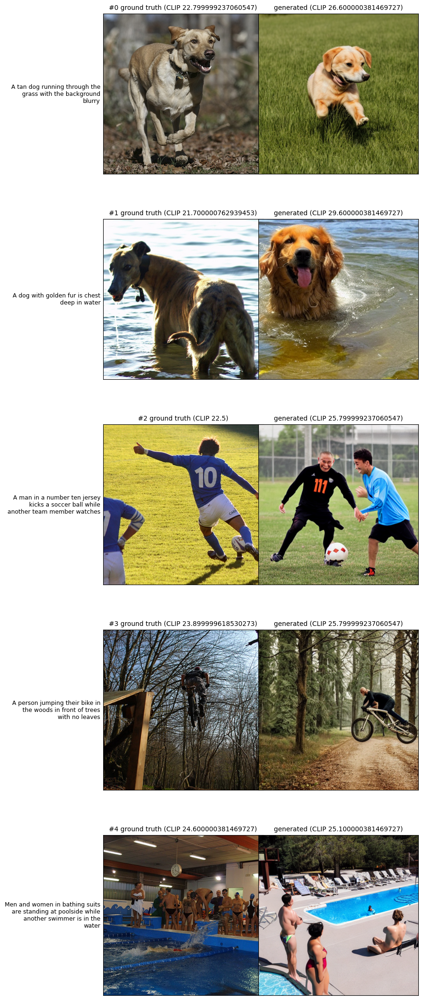

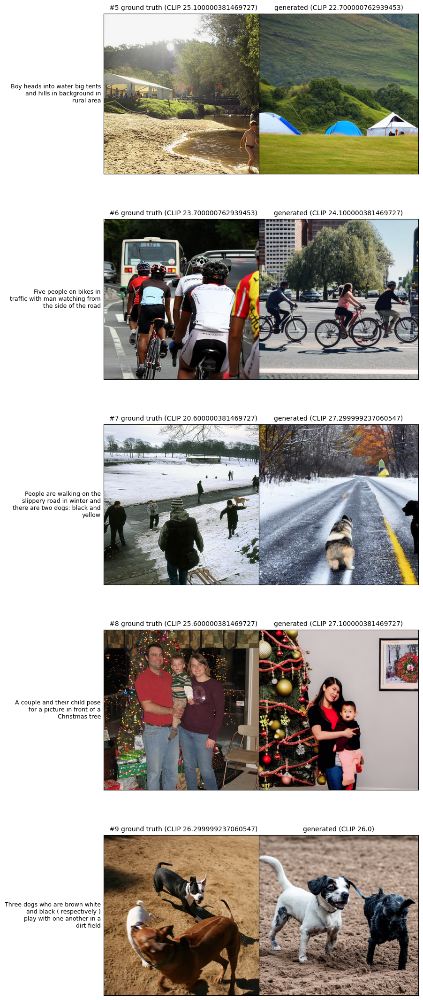

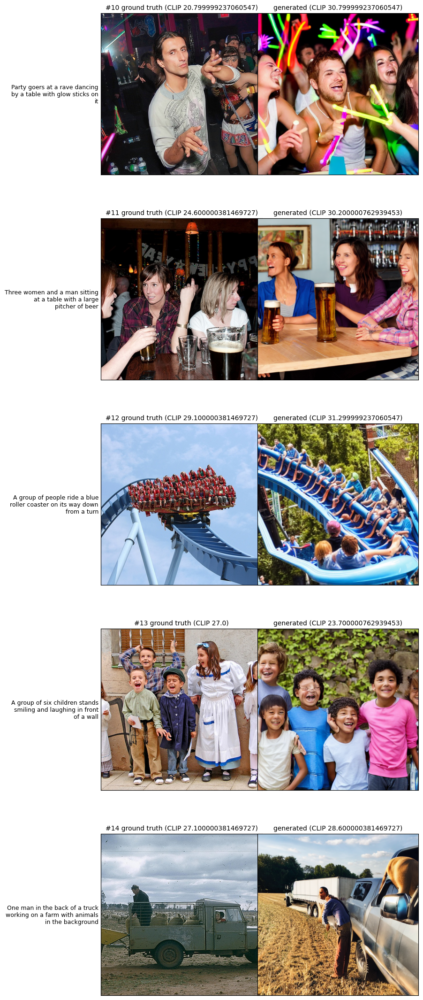

In [8]:
PER_PAGE = 5
page_files = []
for p in range(0, len(gen), PER_PAGE):
    chunk = gen.iloc[p:p + PER_PAGE]
    fig, axes = plt.subplots(len(chunk), 2, figsize=(9, 4.4 * len(chunk)))
    axes = np.atleast_2d(axes)
    for (ax_gt, ax_gen), (_, r), gti, gni in zip(axes, chunk.iterrows(), gt_imgs[p:p+PER_PAGE], gen_imgs[p:p+PER_PAGE]):
        ax_gt.imshow(gti); ax_gen.imshow(gni)
        ax_gt.set_title(f"#{r['id']} ground truth (CLIP {r['clip_groundtruth']})", fontsize=10)
        ax_gen.set_title(f"generated (CLIP {r['clip_generated']})", fontsize=10)
        ax_gt.set_ylabel("\n".join(textwrap.wrap(r["caption"], 30)), fontsize=9, rotation=0, ha="right", va="center")
        for a in (ax_gt, ax_gen): a.set_xticks([]); a.set_yticks([])
    plt.tight_layout()
    fname = f"gallery_page_{p // PER_PAGE + 1}.png"
    plt.savefig(os.path.join(OUT_DIR, fname), dpi=100, bbox_inches="tight"); plt.show()
    page_files.append(fname)

## 9. Diversity test (mode collapse check)
**Mode collapse** means a generative model keeps producing nearly the same output and ignores the variety in the data. To check, we generate **4 images for the same prompt with different seeds** for 3 prompts. If the images look varied and their CLIP image-to-image similarity is moderate, the model is not collapsing.

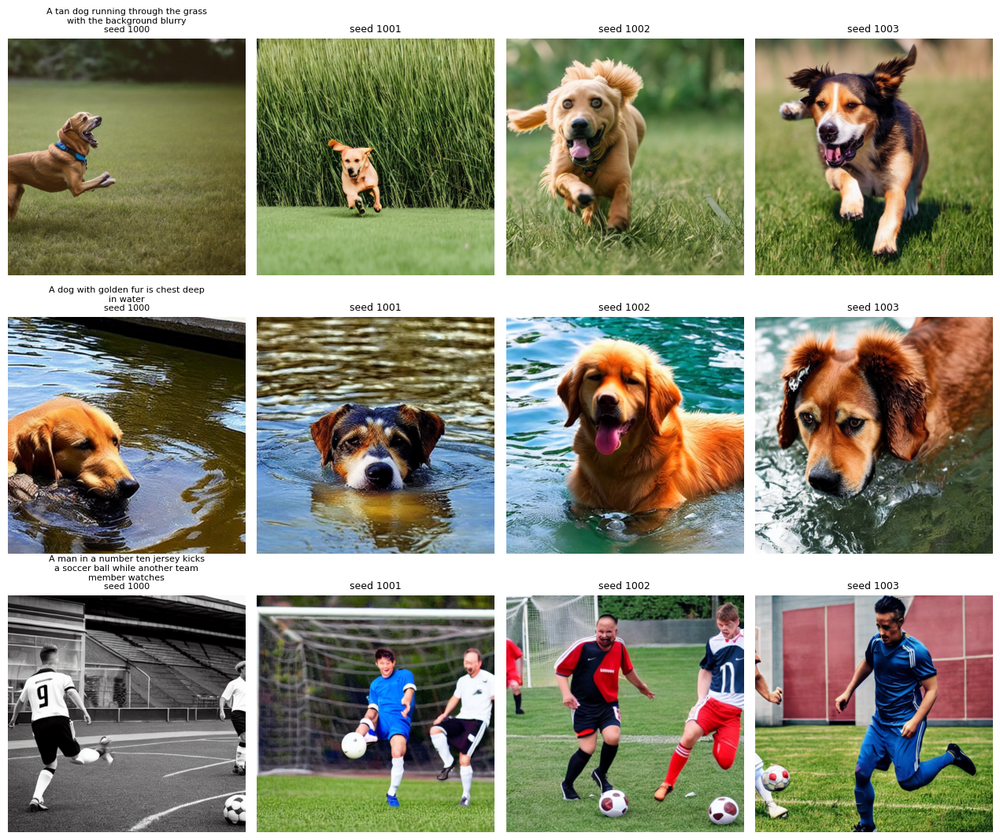

,id,caption,mean_pairwise_img_sim
0,0,A tan dog running through the grass with the background blurry,93.0
1,1,A dog with golden fur is chest deep in water,88.1
2,2,A man in a number ten jersey kicks a soccer ball while another team member watches,81.8


Rough guide: ~95+ = near-identical (collapse risk); 60–85 = same subject, varied composition.


In [9]:
DIV_PROMPTS, DIV_SEEDS = 3, 4
div_rows = []
fig, axes = plt.subplots(DIV_PROMPTS, DIV_SEEDS, figsize=(3.2 * DIV_SEEDS, 3.6 * DIV_PROMPTS))
for row_axes, (_, r) in zip(axes, gen.head(DIV_PROMPTS).iterrows()):
    imgs = []
    for k, ax in enumerate(row_axes):
        g = torch.Generator(device=device).manual_seed(1000 + k)
        img = pipe(r["caption"], num_inference_steps=STEPS, guidance_scale=GUIDANCE_SCALE, generator=g).images[0]
        img.save(os.path.join(OUT_DIR, "generated", f"div_{r['id']:02d}_seed{1000 + k}.png"))
        imgs.append(img); ax.imshow(img); ax.axis("off"); ax.set_title(f"seed {1000 + k}", fontsize=9)
    row_axes[0].set_title("\n".join(textwrap.wrap(r["caption"], 35)) + "\nseed 1000", fontsize=8)
    e = clip_image(imgs)
    pair = (e @ e.T)[~torch.eye(len(imgs), dtype=bool, device=e.device)]
    div_rows.append({"id": r["id"], "caption": r["caption"], "mean_pairwise_img_sim": round(100 * pair.mean().item(), 1)})
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "diversity_grid.png"), dpi=100, bbox_inches="tight"); plt.show()

div = pd.DataFrame(div_rows)
display(div)
print("Rough guide: ~95+ = near-identical (collapse risk); 60–85 = same subject, varied composition.")

## 10. Checks, and save everything
Writes `results.csv`, `summary.json`, and `baseline_gallery.md` (the gallery with scores, ready to export as PDF or view on GitHub). The written analysis for the memo goes in that file's last section.

In [10]:
assert len(gen) == N_PROMPTS, "not all prompts were generated"
for f in gen["gen_file"]:
    with Image.open(os.path.join(OUT_DIR, "generated", f)) as im:
        assert im.size == (SIZE, SIZE), f"bad size: {f}"
print(f"All {len(gen)} prompts generated successfully at {SIZE}x{SIZE}.")

gen.to_csv(os.path.join(OUT_DIR, "results.csv"), index=False)
summary = {
    "sd_model": SD_MODEL, "clip_model": CLIP_MODEL, "steps": STEPS, "guidance_scale": GUIDANCE_SCALE,
    "seed": SEED, "n_prompts": len(gen), "scheduler": type(pipe.scheduler).__name__,
    "mean_clip_generated": float(gen["clip_generated"].mean()),
    "mean_clip_groundtruth": float(gen["clip_groundtruth"].mean()),
    "mean_img_similarity": float(gen["img_similarity"].mean()),
    "mean_seconds_per_image": float(gen["seconds"].mean()),
    "safety_flagged": int(gen["safety_flagged"].sum()),
    "diversity": div.to_dict(orient="records"),
}
with open(os.path.join(OUT_DIR, "summary.json"), "w") as f:
    json.dump(summary, f, indent=2)

lines = ["# Baseline Generation Gallery — Stable Diffusion 1.5", "",
         f"Model `{SD_MODEL}` · {STEPS} steps · guidance {GUIDANCE_SCALE} · seed {SEED}+i · {SIZE}×{SIZE}", "",
         f"Mean CLIP score: generated **{summary['mean_clip_generated']:.1f}** vs ground truth "
         f"**{summary['mean_clip_groundtruth']:.1f}** · mean generated↔real image similarity "
         f"**{summary['mean_img_similarity']:.1f}**", "",
         "| # | Domain | Prompt | Ground truth | Generated | CLIP (gen) | CLIP (GT) |", "|---|---|---|---|---|---|---|"]
for _, r in gen.iterrows():
    lines.append(f"| {r['id']} | {r['domain']} | {r['caption']} | "
                 f"<img src='../{DATA_DIR}/images/{r['gt_file']}' width='160'> | "
                 f"<img src='generated/{r['gen_file']}' width='160'> | {r['clip_generated']} | {r['clip_groundtruth']} |")
lines += ["", "## Diversity test (same prompt, 4 seeds)", "", "![diversity](diversity_grid.png)", "",
          "| Prompt | Mean pairwise image similarity |", "|---|---|"]
lines += [f"| {r['caption']} | {r['mean_pairwise_img_sim']} |" for _, r in div.iterrows()]
lines += ["", "## Qualitative analysis", "", "_(to be written from the results above)_"]
with open(os.path.join(OUT_DIR, "baseline_gallery.md"), "w") as f:
    f.write("\n".join(lines))

print(sorted(os.listdir(OUT_DIR)))

All 15 prompts generated successfully at 512x512.
['baseline_gallery.md', 'diversity_grid.png', 'gallery_page_1.png', 'gallery_page_2.png', 'gallery_page_3.png', 'generated', 'results.csv', 'summary.json']


## 11. Download the results
Zip the gallery folder so it can go into the GitHub repo and the memo.

In [11]:
shutil.make_archive("baseline_gallery", "zip", OUT_DIR)
print("Created baseline_gallery.zip")
# from google.colab import files; files.download("baseline_gallery.zip")

Created baseline_gallery.zip
